In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
import cv2

In [2]:
# Exibe uma janela para a seleção de um arquivo
from google.colab import files
arquivo = files.upload()
img_name = next(iter(arquivo))

# Leitura da imagem pelo cv2, convertido para tons de cinza
imagem = cv2.imread(img_name, cv2.IMREAD_GRAYSCALE)

Saving Lenna.png to Lenna.png


Limiarização Global Manual

(np.float64(-0.5), np.float64(511.5), np.float64(511.5), np.float64(-0.5))

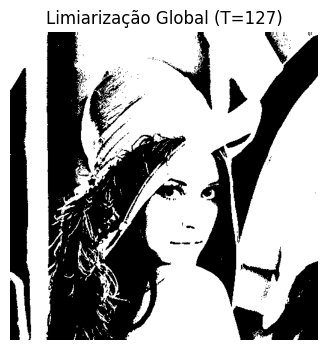

In [5]:
# Definir limiar
T = 127

# Criar matriz de saída inicialmente preenchida com zeros
altura, largura = imagem.shape
resultado_global = np.zeros((altura, largura), dtype=np.uint8)

# Percorrer todos os pixels
for i in range(altura):
    for j in range(largura):

        if imagem[i, j] > T:
            resultado_global[i, j] = 255
        else:
            resultado_global[i, j] = 0

# Exibir resultado
plt.figure(figsize=(4,4))
plt.imshow(resultado_global, cmap="gray")
plt.title(f"Limiarização Global (T={T})")
plt.axis("off")

Adaptive Mean Threshold

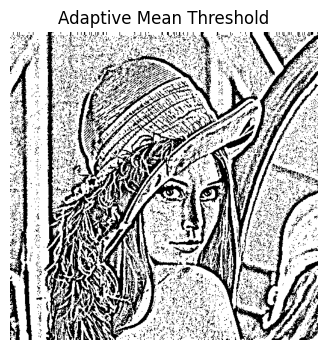

In [7]:

# Parâmetros
block_size = 11
# Constante de Ajuste
C = 2

# Dados da imagem
altura, largura = imagem.shape

# Criar imagem de saída
resultado_mean = np.zeros((altura, largura), dtype=np.uint8)

# Definir o tamanho da margem
margem = block_size // 2

# Adicionar bordas para permitir a análise dos pixels extremos
imagem_padded = np.pad(imagem,margem,mode="reflect")

# Percorrer os pixels da imagem original
for i in range(altura):
    for j in range(largura):

        # Extrair a vizinhança do pixel atual
        regiao = imagem_padded[i:i + block_size, j:j + block_size]

        # Calcular a média da vizinhança
        media = np.mean(regiao)

        # Calcular o limiar local
        T_local = media - C

        # Comparar o pixel central com o limiar local
        if imagem[i, j] > T_local:
            resultado_mean[i, j] = 255
        else:
            resultado_mean[i, j] = 0

# Exibir resultado
plt.figure(figsize=(4,4))
plt.imshow(resultado_mean, cmap="gray")
plt.title("Adaptive Mean Threshold")
plt.axis("off")
plt.show()


Construção do histograma

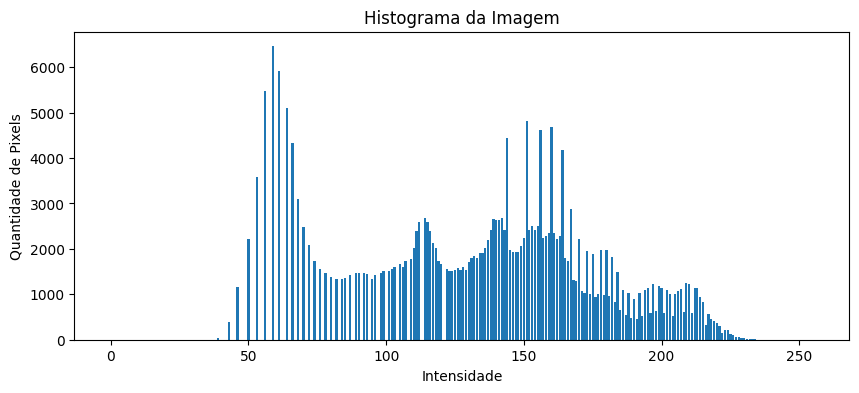

In [8]:

# Criar histograma com 256 posições
histograma = np.zeros(256, dtype=np.int64)

# Contar quantos pixels existem em cada intensidade
for i in range(imagem.shape[0]):
    for j in range(imagem.shape[1]):

        intensidade = imagem[i, j]
        histograma[intensidade] += 1

# Exibir histograma
plt.figure(figsize=(10, 4))
plt.bar(range(256), histograma)
plt.title("Histograma da Imagem")
plt.xlabel("Intensidade")
plt.ylabel("Quantidade de Pixels")

plt.show()


Cálculo do limiar ideal


In [15]:

# Quantidade total de pixels
total_pixels = imagem.size

# Média global da imagem
media_global = np.sum(histograma) / total_pixels

# Inicializar variáveis
maior_variancia = -1
melhor_limiar = 0

# Testar os possíveis limiares
for T in range(256):

    # Classe 0: pixels menores ou iguais a T
    pixelsC0 = np.sum(histograma[:T+1])

    # Classe 1: pixels maiores que T
    pixelsC1 = total_pixels - pixelsC0

    # Evitar classes vazias
    if pixelsC0 == 0 or pixelsC1 == 0:
        continue

    # Proporção de cada classe
    w0 = pixelsC0 / total_pixels
    w1 = pixelsC1 / total_pixels

    # Média da Classe 0
    media0 = np.sum(np.arange(T+1) * histograma[:T+1]) / pixelsC0

    # Média da Classe 1
    media1 = np.sum(np.arange(T+1, 256) * histograma[T+1:]) / pixelsC1

    # Variância entre classes
    variancia = (w0 * (media0 - media_global)**2 +
                 w1 * (media1 - media_global)**2)

    # Verificar se encontramos uma variância maior
    if variancia > maior_variancia:
        maior_variancia = variancia
        melhor_limiar = T

print("Melhor limiar encontrado:", melhor_limiar)
print("Maior variância entre classes:", maior_variancia)


Melhor limiar encontrado: 124
Maior variância entre classes: 18696.97091958548


Aplicar o limiar encontrado

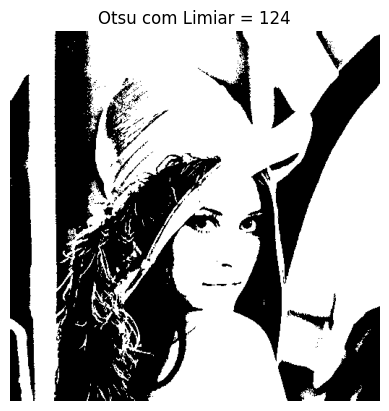

In [17]:

# Criar imagem de saída
resultado_otsu = np.zeros(imagem.shape,dtype=np.uint8)

# Aplicar o limiar encontrado
for i in range(imagem.shape[0]):
    for j in range(imagem.shape[1]):

        if imagem[i, j] > melhor_limiar:
            resultado_otsu[i, j] = 255
        else:
            resultado_otsu[i, j] = 0

# Exibir resultado
plt.imshow(resultado_otsu, cmap="gray")
plt.title(f"Otsu com Limiar = {melhor_limiar}")
plt.axis("off")
plt.show()
